# 02 · Preparación de los datos
**Proyecto Visión por Computador — CRISP-DM etapa 3**

Esta etapa transforma un dataset con **etiquetas discretas** (46 nombres de tono) en un problema de **estimación de color continuo en CIELAB**, que es lo que necesita el negocio: los clientes piden *cualquier* color y el catálogo de colorantes se compara en Lab.

| Reto del planteamiento inicial | Cómo se atiende | Dónde |
|---|---|---|
| El dataset usa clases discretas, pero la empresa recibe cualquier color | El objetivo pasa a ser el **color Lab medido** de la prenda; la etiqueta solo ancla y filtra | §4, §5 |
| Definir cómo pasar de etiquetas discretas a CIELAB continuo | Prototipo continuo por tono + filtro de coherencia etiqueta–medición | §5 |
| ¿Qué ocurre con los productos de varios colores? | Paleta por k-means, regla de multicolor validada con la etiqueta `Multi` | §6 |
| La máscara por umbral no existe en el contexto real | Segmentación aprendida de prendas (sirve en cualquier foto) y modelos que **no usan máscara** al predecir; prueba con fotos de cliente simuladas | §2, §7 |
| Elementos del dominio que afectan el color / correlación con metadatos | Notebook `03_exploracion_complementaria` | — |

Los cálculos pesados están en `ejecutar_pipeline.py` (con caché); este notebook los lee y los analiza.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from core import config
from core.datos import decodificar
from core.color import lab_a_rgb

config.RUTA_FIGURAS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 150})
rng = np.random.default_rng(config.SEMILLA)

def guardar(nombre):
    plt.savefig(config.RUTA_FIGURAS / f"{nombre}.png")

from core.preparacion import cargar_prendas, cargar_tabla
from core.segmentacion import segmentar_dataset, mascara_prenda, mascara_persona
from core.color import mascara_primer_plano
from core.objetivo_color import balance_blancos, medir_color_prenda
from core.perturbaciones import simular_foto_real

ok, df, msg = cargar_prendas(); print(msg); assert ok, msg
bytes_por_id = df.set_index("id")["imagen_bytes"]
mapas = segmentar_dataset(df)
tabla, proto = cargar_tabla()
print(f"Tabla: {tabla.shape} · prototipos de tono: {len(proto)}")

21,361 prendas en el alcance textil (Apparel)


Tabla: (21361, 33) · prototipos de tono: 42


## 1. Alcance textil
El negocio son **colorantes para textiles**. Se conservan solo las prendas (`masterCategory = Apparel`) y se descartan calzado, relojes, joyería, gafas y cuidado personal: no son sustratos textiles y además concentraban los tonos metálicos que en la exploración inicial aparecían como un atajo (tono ↔ tipo de producto).

In [2]:
ok_all, df_all, _ = __import__("core.datos", fromlist=["x"]).cargar_dataset()
resumen = pd.DataFrame({"total": df_all["masterCategory"].value_counts()})
resumen["en_alcance"] = resumen.index.isin(config.ALCANCE_MASTER)
display(resumen)
print("Subcategorías de prenda:"); display(tabla["subCategory"].value_counts().to_frame("prendas"))

,total,en_alcance
masterCategory,,
Apparel,21361,True
Accessories,11244,False
Footwear,9197,False
Personal Care,2139,False
Free Items,105,False
Sporting Goods,25,False
Home,1,False


Subcategorías de prenda:


,prendas
subCategory,
Topwear,15383
Bottomwear,2685
Innerwear,1806
Dress,478
Loungewear and Nightwear,464
Saree,427
Apparel Set,106
Socks,12


## 2. Segmentación de la prenda (sin máscara manual)
En la exploración inicial (notebook 01) la "máscara" era un umbral contra el fondo blanco: no existe en una foto real y además incluía piel, cabello y otras prendas. Aquí se usa un modelo de **human parsing** preentrenado (SegFormer-B2, 18 clases: parte superior, pantalón, falda, vestido, piel, cabello…). Para cada producto se toma la clase que corresponde a su subcategoría (`Topwear` → parte superior, `Bottomwear` → pantalón/falda…). Si la prenda está fotografiada sola (sin modelo) el parser no la reconoce y se usa la máscara por ΔE como respaldo.

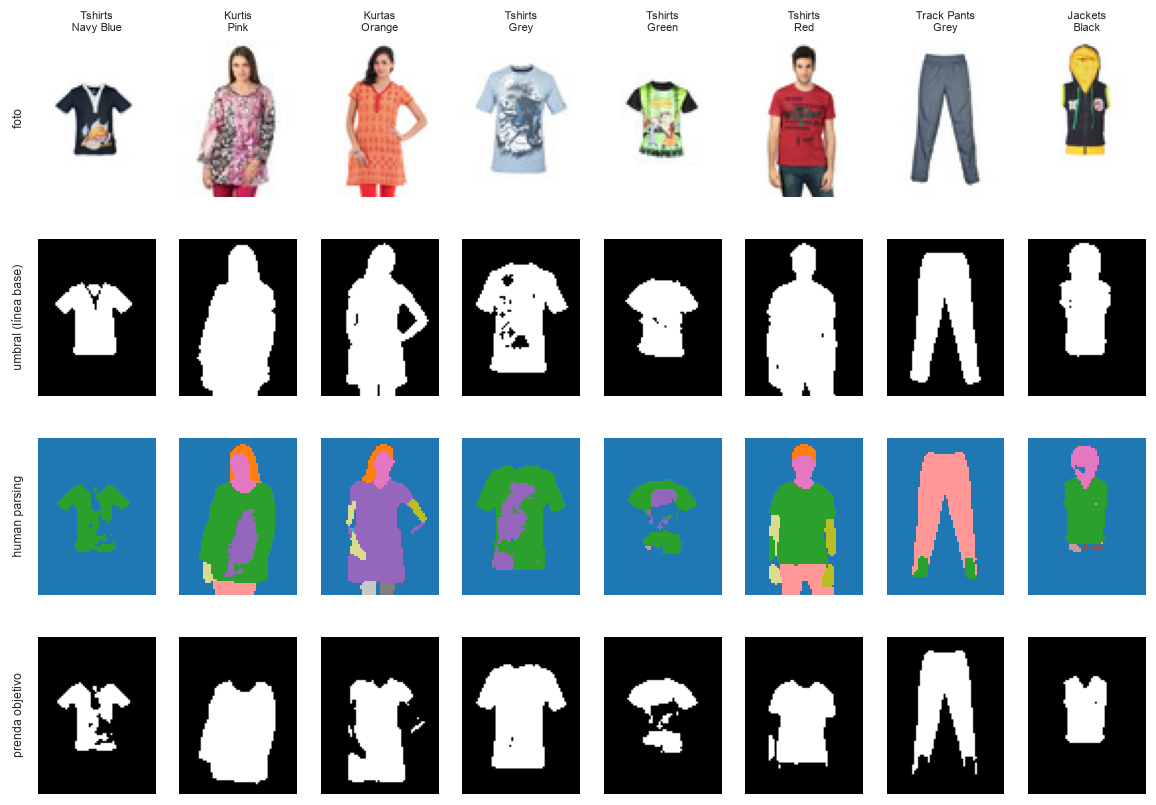

In [3]:
ej = tabla[tabla["subCategory"].isin(["Topwear", "Bottomwear", "Dress"])].sample(8, random_state=4).index
paleta_seg = plt.get_cmap("tab20", 18)
fig, axes = plt.subplots(4, 8, figsize=(13, 9))
for k, pid in enumerate(ej):
    rgb = decodificar(bytes_por_id[pid]); m = mapas[pid]
    umbral, _, _ = mascara_primer_plano(rgb)
    axes[0, k].imshow(rgb); axes[0, k].set_title(f"{tabla.at[pid, 'articleType']}\n{tabla.at[pid, 'baseColour']}", fontsize=7)
    axes[1, k].imshow(umbral, cmap="gray")
    axes[2, k].imshow(m, cmap=paleta_seg, vmin=0, vmax=17, interpolation="nearest")
    axes[3, k].imshow(mascara_prenda(m, tabla.at[pid, "subCategory"]), cmap="gray")
for ax in axes.flat: ax.axis("off")
for fila, t in zip(axes[:, 0], ["foto", "umbral (línea base)", "human parsing", "prenda objetivo"]):
    fila.text(-0.12, 0.5, t, transform=fila.transAxes, rotation=90, va="center", ha="right", fontsize=8)
guardar("p2_segmentacion"); plt.show()

In [4]:
print("Origen de la máscara de prenda:"); display(tabla["fuente_mascara"].value_counts().to_frame("prendas"))
print("Fracción de la imagen que es prenda (mediana por subcategoría):")
display(tabla.groupby("subCategory")["frac_prenda"].median().round(3).to_frame())
# ¿Cuánta piel/cabello/otras prendas incluía la máscara por umbral (línea base)?
muestra = tabla.sample(1500, random_state=1).index
contam = []
for pid in muestra:
    rgb = decodificar(bytes_por_id[pid]); m = mapas[pid]
    umbral, _, _ = mascara_primer_plano(rgb)
    prenda = mascara_prenda(m, tabla.at[pid, "subCategory"])
    if umbral.sum():
        contam.append(1 - (umbral & prenda).sum() / umbral.sum())
print(f"En la máscara por umbral, {np.mean(contam):.0%} de los píxeles (media) NO eran la prenda objetivo")

Origen de la máscara de prenda:


,prendas
fuente_mascara,
segmentacion,20777
umbral_fondo,584


Fracción de la imagen que es prenda (mediana por subcategoría):


,frac_prenda
subCategory,
Apparel Set,0.159
Bottomwear,0.201
Dress,0.214
Innerwear,0.145
Loungewear and Nightwear,0.183
Saree,0.251
Socks,0.241
Topwear,0.266


En la máscara por umbral, 45% de los píxeles (media) NO eran la prenda objetivo


## 3. Constancia de color: balance de blancos con el fondo
La misma prenda se ve distinta bajo luz cálida o fría. En las fotos de catálogo el fondo es blanco, así que sirve como **referencia neutra**: se estima el iluminante con los píxeles de fondo claros y se corrige con el modelo de **Von Kries** (ganancias por canal en RGB lineal). Las ganancias muestran cuánta dominante de color tenía cada foto.

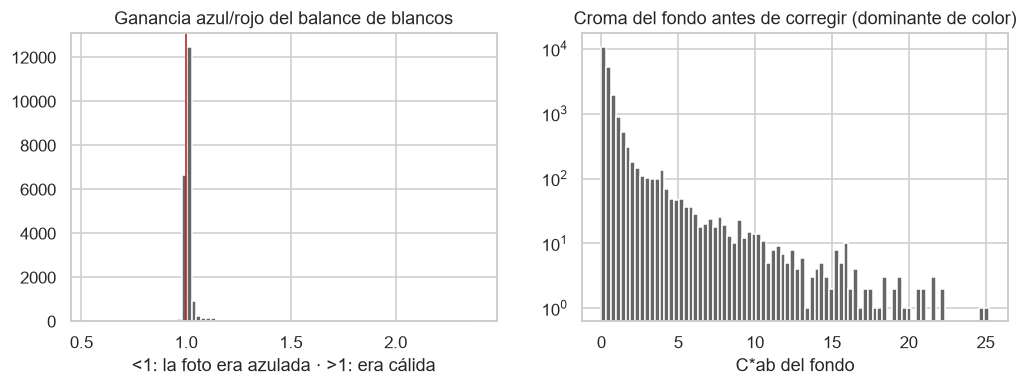

Fotos con dominante visible (croma del fondo > 3): 4.9%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(tabla["ganancia_b"] / tabla["ganancia_r"], bins=80, color="0.4")
axes[0].axvline(1, color="firebrick", lw=1)
axes[0].set(title="Ganancia azul/rojo del balance de blancos", xlabel="<1: la foto era azulada · >1: era cálida")
axes[1].hist(tabla["croma_fondo"].dropna(), bins=80, color="0.4"); axes[1].set_yscale("log")
axes[1].set(title="Croma del fondo antes de corregir (dominante de color)", xlabel="C*ab del fondo")
guardar("p2_balance_blancos"); plt.show()
print(f"Fotos con dominante visible (croma del fondo > 3): {(tabla['croma_fondo'] > 3).mean():.1%}")

## 4. Objetivo continuo: color dominante de la prenda en CIELAB
Sobre los píxeles de la prenda (ya con balance de blancos) se aplica **k-means con k = 3 en CIELAB**. El grupo más grande es el **color dominante** y su mediana es el **objetivo continuo** (L\*, a\*, b\*). Los otros grupos forman la **paleta** de la prenda (sombras, estampados, segundo color).

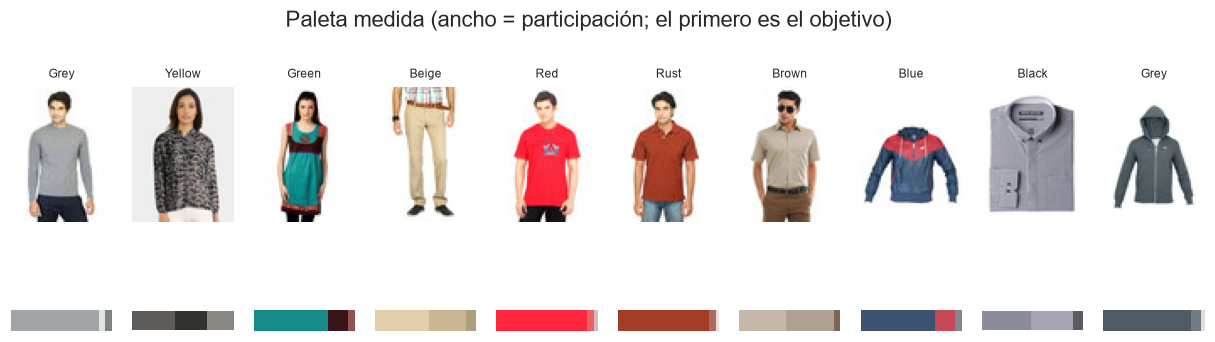

In [6]:
ej = tabla[tabla["tiene_objetivo"]].sample(10, random_state=11).index
fig, axes = plt.subplots(2, 10, figsize=(14, 3.6), gridspec_kw={"height_ratios": [3, 1]})
for k, pid in enumerate(ej):
    axes[0, k].imshow(decodificar(bytes_por_id[pid])); axes[0, k].set_title(tabla.at[pid, "baseColour"], fontsize=8)
    pal = np.array(tabla.at[pid, "paleta"].tolist()); part = np.array(tabla.at[pid, "paleta_part"])
    barra = np.concatenate([np.ones((6, max(1, int(round(p * 30))), 3)) * lab_a_rgb(cc)[0] for cc, p in zip(pal, part)], axis=1)
    axes[1, k].imshow(barra)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Paleta medida (ancho = participación; el primero es el objetivo)")
guardar("p2_paletas"); plt.show()

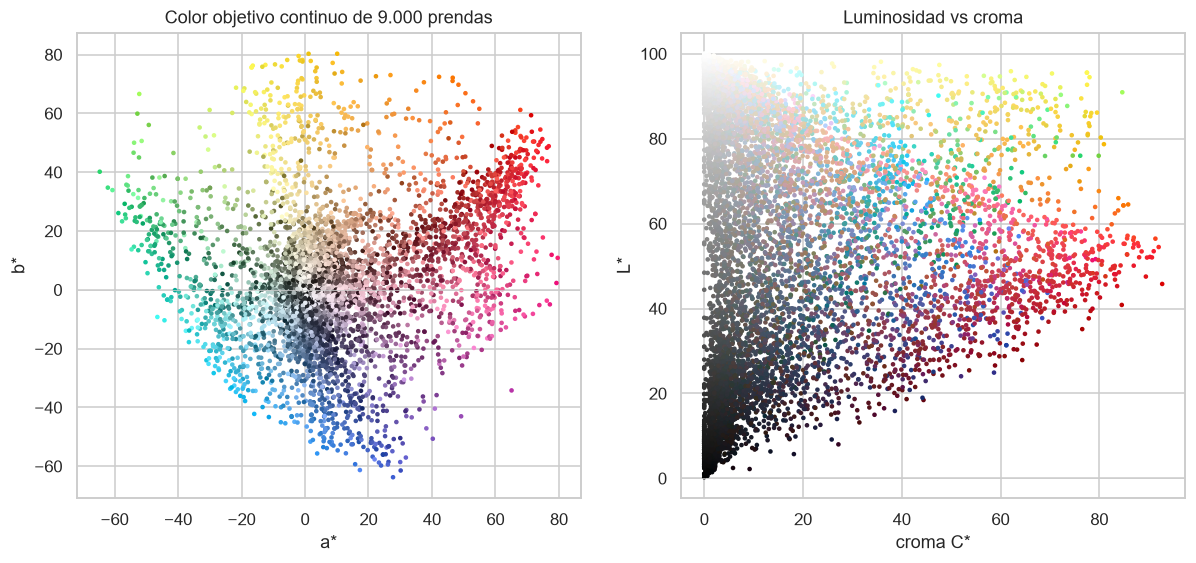

In [7]:
v = tabla[tabla["tiene_objetivo"]].sample(9000, random_state=2)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(v["a_obj"], v["b_obj"], c=lab_a_rgb(v[["L_obj", "a_obj", "b_obj"]].values), s=4)
axes[0].set(xlabel="a*", ylabel="b*", title="Color objetivo continuo de 9.000 prendas")
axes[1].scatter(v["C_obj"], v["L_obj"], c=lab_a_rgb(v[["L_obj", "a_obj", "b_obj"]].values), s=4)
axes[1].set(xlabel="croma C*", ylabel="L*", title="Luminosidad vs croma")
for ax in axes: ax.axhline(0, c="0.8", lw=.5)
guardar("p2_objetivo_continuo"); plt.show()

## 5. De la etiqueta discreta al espacio CIELAB continuo
La etiqueta `baseColour` no se usa como clase a predecir, sino como **ancla**:

1. **Prototipo por tono:** para cada nombre se calcula la mediana Lab de los colores medidos (solo prendas de un color, partición de entrenamiento). Así, cada nombre ocupa una **región** del espacio continuo, no un punto fijo.
2. **Filtro de coherencia:** un color medido se acepta como objetivo de entrenamiento si el prototipo de su etiqueta está entre los 5 más cercanos (ΔE2000). Lo que no cumple es ruido de etiqueta o de segmentación.
3. **Predicción:** el modelo predice un **Lab continuo**; el nombre de tono (cuando se necesite comunicarlo) es el prototipo más cercano, y la referencia del catálogo se busca por ΔE2000, sin depender de los 46 nombres. Así se atiende cualquier color que pida el cliente.

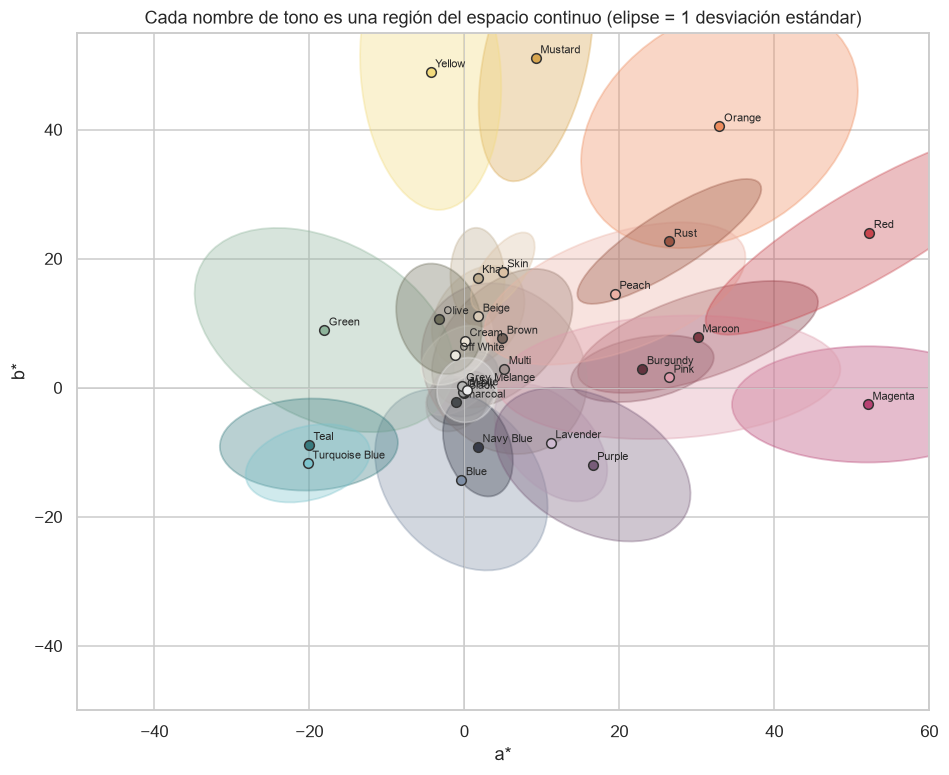

In [8]:
from matplotlib.patches import Ellipse
fig, ax = plt.subplots(figsize=(10, 8))
base = tabla[tabla["tiene_objetivo"] & ~tabla["multicolor"].astype(bool) & (tabla["split"] == "train")]
for tono, r in proto[proto["n"] >= 15].iterrows():
    pts = base.loc[base["baseColour"] == tono, ["a_obj", "b_obj"]].to_numpy()
    cov = np.cov(pts.T); val, vec = np.linalg.eigh(cov)
    ang = np.degrees(np.arctan2(vec[1, 1], vec[0, 1]))
    col = lab_a_rgb(r[["L", "a", "b"]].to_numpy(float))[0]
    ax.add_patch(Ellipse((r["a"], r["b"]), 2 * np.sqrt(val[1]), 2 * np.sqrt(val[0]), angle=ang,
                         facecolor=col, alpha=0.35, edgecolor=col, lw=1.2))
    ax.scatter(r["a"], r["b"], color=col, edgecolor="0.2", s=40, zorder=3)
    ax.annotate(tono, (r["a"], r["b"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlim=(-50, 60), ylim=(-50, 55), xlabel="a*", ylabel="b*",
       title="Cada nombre de tono es una región del espacio continuo (elipse = 1 desviación estándar)")
ax.axhline(0, c="0.8", lw=.5); ax.axvline(0, c="0.8", lw=.5)
guardar("p2_regiones_tono"); plt.show()

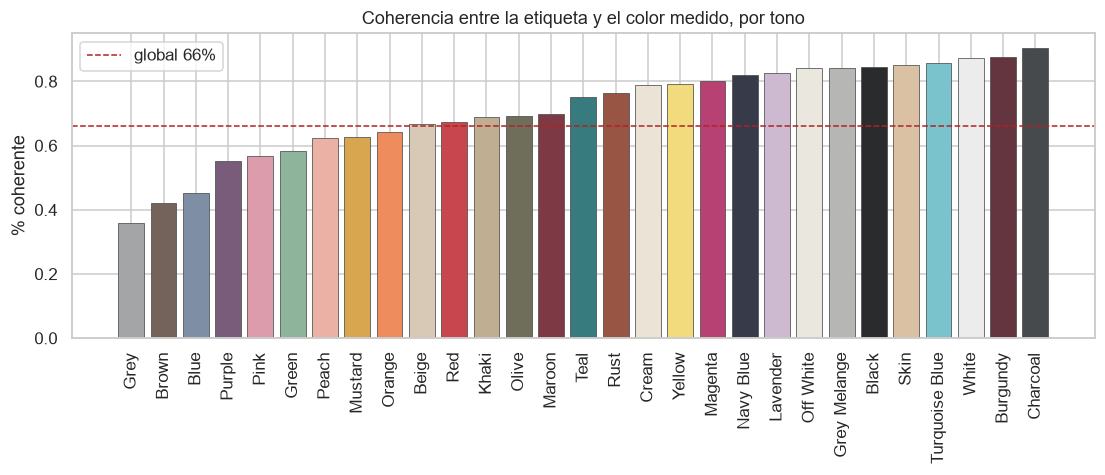

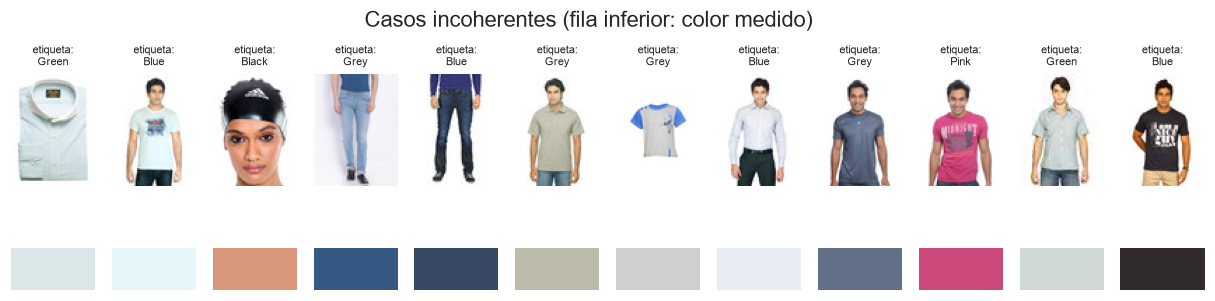

In [9]:
t = tabla[tabla["tiene_objetivo"] & ~tabla["grupo_color"].isin(["Multi"])]
coh = t.groupby("baseColour")["coherente"].agg(["mean", "size"]).sort_values("mean")
coh = coh[coh["size"] >= 20]
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(coh.index, coh["mean"], color=[lab_a_rgb(proto.loc[i, ["L", "a", "b"]].to_numpy(float))[0] for i in coh.index], edgecolor="0.3", lw=.5)
ax.axhline(t["coherente"].mean(), color="firebrick", lw=1, ls="--", label=f"global {t['coherente'].mean():.0%}")
ax.tick_params(axis="x", rotation=90); ax.set_ylabel("% coherente"); ax.legend()
ax.set_title("Coherencia entre la etiqueta y el color medido, por tono")
guardar("p2_coherencia"); plt.show()

inco = t[~t["coherente"]].sample(12, random_state=3)
fig, axes = plt.subplots(2, 12, figsize=(14, 3), gridspec_kw={"height_ratios": [3, 1]})
for k, (pid, r) in enumerate(inco.iterrows()):
    axes[0, k].imshow(decodificar(bytes_por_id[pid])); axes[0, k].set_title(f"etiqueta:\n{r.baseColour}", fontsize=7)
    axes[1, k].imshow(np.ones((4, 8, 3)) * lab_a_rgb(r[["L_obj", "a_obj", "b_obj"]].to_numpy(float))[0])
for ax in axes.flat: ax.axis("off")
plt.suptitle("Casos incoherentes (fila inferior: color medido)"); guardar("p2_incoherentes"); plt.show()

## 6. Prendas de varios colores
Regla: una prenda es **multicolor** si el segundo color de la paleta ocupa ≥ 25 % de la prenda **y** está a ΔE2000 ≥ 20 del dominante. Se valida contra la etiqueta `Multi` del dataset, que nunca se usó para definir la regla.

Tratamiento en el negocio: para una prenda multicolor no se entrega un solo color sino la **paleta** (cada color con su participación), y el comercial elige cuál igualar. Para entrenar el regresor del color dominante se excluyen, porque su "color objetivo" es ambiguo.

In [10]:
from sklearn.metrics import roc_auc_score
t = tabla[tabla["tiene_objetivo"]].copy()
t["score_multi"] = t["part_2"] * t["dE_12"]
es_multi = t["baseColour"] == "Multi"
print(f"Prendas multicolor según la regla: {t['multicolor'].mean():.1%}")
print(f"  entre las etiquetadas 'Multi': {t.loc[es_multi, 'multicolor'].mean():.0%} · entre las demás: {t.loc[~es_multi, 'multicolor'].mean():.0%}")
print(f"AUC del puntaje (participación del 2.º color × ΔE) para detectar 'Multi': {roc_auc_score(es_multi, t['score_multi']):.2f}")
display(t.groupby("subCategory")["multicolor"].mean().sort_values(ascending=False).round(3).to_frame("% multicolor"))

Prendas multicolor según la regla: 12.0%
  entre las etiquetadas 'Multi': 49% · entre las demás: 12%


AUC del puntaje (participación del 2.º color × ΔE) para detectar 'Multi': 0.80


,% multicolor
subCategory,
Saree,0.457
Apparel Set,0.425
Loungewear and Nightwear,0.278
Innerwear,0.211
Dress,0.132
Topwear,0.106
Bottomwear,0.044
Socks,0.000


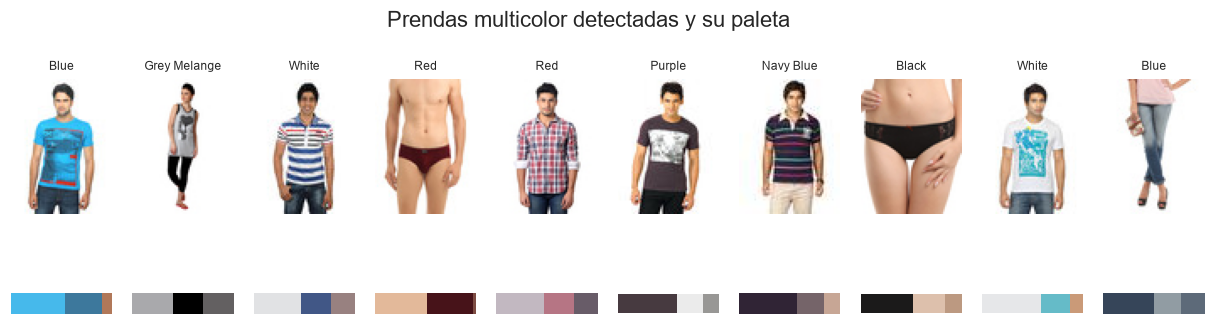

In [11]:
mc = t[t["multicolor"]].sample(10, random_state=5)
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4), gridspec_kw={"height_ratios": [3, 1]})
for k, (pid, r) in enumerate(mc.iterrows()):
    axes[0, k].imshow(decodificar(bytes_por_id[pid])); axes[0, k].set_title(r.baseColour, fontsize=8)
    pal = np.array(r["paleta"].tolist()); part = np.array(r["paleta_part"])
    barra = np.concatenate([np.ones((6, max(1, int(round(p * 30))), 3)) * lab_a_rgb(cc)[0] for cc, p in zip(pal, part)], axis=1)
    axes[1, k].imshow(barra)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Prendas multicolor detectadas y su paleta"); guardar("p2_multicolor"); plt.show()

## 7. Conjuntos de entrenamiento, validación y prueba
Se conserva la partición definida en el notebook 01 (estratificada por tono y agrupada por casi-duplicados, sin fuga de datos).

* **Entrenamiento / validación:** prendas con objetivo, coherentes, de un solo color y sin los grupos `Multi`/`Metálico`.
* **Prueba (catálogo):** todas las prendas de test con objetivo (incluye incoherentes y multicolor, para no maquillar el resultado).
* **Prueba "contexto real":** las mismas prendas de test convertidas en *fotos de cliente*: fondo arbitrario (sólido, degradado o textura), iluminante entre 3.000 K y 7.500 K, exposición ±25 % y compresión JPEG. El objetivo sigue siendo el color bajo luz de estudio: el modelo debe ser **color-constante**.

In [12]:
roles = pd.crosstab(tabla["split"], [tabla["uso_entrenamiento"]]).rename(columns={True: "usable para entrenar", False: "excluida"})
display(roles)
print("Motivo de exclusión (train):")
tr = tabla[tabla["split"] == "train"]
motivos = pd.Series({
    "sin objetivo": (~tr["tiene_objetivo"]).sum(),
    "multicolor": tr["multicolor"].fillna(False).astype(bool).sum(),
    "incoherente con la etiqueta": (tr["tiene_objetivo"] & ~tr["coherente"]).sum(),
    "Multi / Metálico": tr["grupo_color"].isin(["Multi", "Metálico"]).sum()})
display(motivos.to_frame("prendas"))

uso_entrenamiento,excluida,usable para entrenar
split,,
test,1244,1806
train,6156,9110
val,1240,1805


Motivo de exclusión (train):


,prendas
sin objetivo,0
multicolor,1812
incoherente con la etiqueta,5236
Multi / Metálico,198


Fotos de contexto real: 3,010


,count,unique,top,mean,min,max
fondo,3010,3,degradado,NaN,NaN,NaN
kelvin,3010.0,NaN,NaN,5254.178405,3000.0,7499.0
brillo,3010.0,NaN,NaN,0.974638,0.75,1.2
jpeg,3010.0,NaN,NaN,54.650498,35.0,74.0


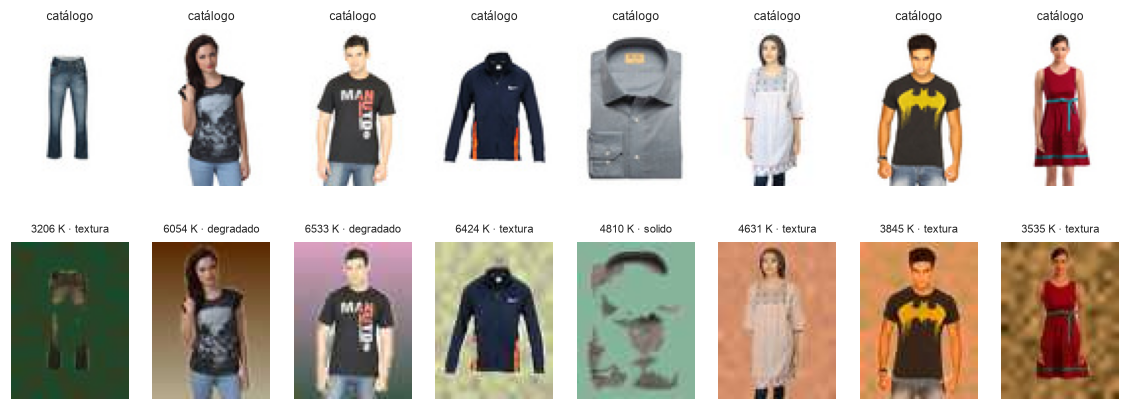

In [13]:
from core.preparacion import RUTA_TEST_REAL
real = pd.read_parquet(RUTA_TEST_REAL)
print(f"Fotos de contexto real: {len(real):,}")
display(real[["fondo", "kelvin", "brillo", "jpeg"]].describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]])
ej = real.sample(8, random_state=1)
fig, axes = plt.subplots(2, 8, figsize=(13, 4.6))
for k, (_, r) in enumerate(ej.iterrows()):
    axes[0, k].imshow(decodificar(bytes_por_id[r["id"]])); axes[0, k].set_title("catálogo", fontsize=8)
    axes[1, k].imshow(decodificar(r["imagen_bytes"])); axes[1, k].set_title(f"{r['kelvin']} K · {r['fondo']}", fontsize=7)
for ax in axes.flat: ax.axis("off")
guardar("p2_contexto_real"); plt.show()

## 8. Resumen de decisiones de preparación
| Decisión | Justificación |
|---|---|
| Solo prendas (21.361) | El sustrato del negocio es textil; elimina el atajo tono–categoría de los metálicos |
| Segmentación aprendida de la prenda | Funciona en cualquier foto y excluye piel, cabello y otras prendas |
| Balance de blancos con el fondo (Von Kries) | Constancia de color: el objetivo representa el color bajo luz neutra |
| Objetivo = color dominante Lab (k-means k = 3) | Variable continua: permite atender cualquier color, no solo 46 nombres |
| Etiqueta como ancla + filtro de coherencia | Convierte la etiqueta discreta en una región Lab y limpia el ruido |
| Multicolor por regla validada con `Multi` | Se entrega la paleta; se excluye del regresor del color dominante |
| Prueba en contexto real simulado | Mide lo que pasaría con fotos de clientes (fondo, luz, compresión) |